[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_oschains.ipynb)


# Small oscillations of chains with $N\gg1$

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

An elastic medium can be modelled as material points coupled by Hooke’s-law forces. Such systems support travelling waves, including sound. Simple chains illustrate the underlying mechanisms.

The Lagrangian of $N$ masses connected by springs is

$$
L=\frac{1}{2}\sum m{\dot{\mathbf{r}}}_{n}^{2}-\frac{1}{2}{\sum }_{m,n}^{N}{k}_{mn}.\left({\mathbf{r}}_{m}-{\mathbf{r}}_{n}\right).\left({\mathbf{r}}_{m}-{\mathbf{r}}_{n}\right)
$$

where ${\mathbf{r}}_{n}$ is the displacement from the equilibrium position ${\mathbf{r}}_{n}^{\left(0\right)}$ and the sum in potential term is over the nearest neighbours.

$$
\frac{d}{dt}\left(\frac{\partial L}{\partial  \dot{q} }\right)-\frac{\partial L}{\partial  q }\Rightarrow m{\ddot{\mathbf{r}}}_{n}+\underset{j}{\sum }{k}_{nj}.\left({\mathbf{r}}_{n}-{\mathbf{r}}_{j}\right)=0
$$

Because the equations are linear, seek a solution of the form

$$
{\mathbf{r}}_{n}={\mathbf{u}}_{\omega }^{\left(n\right)} {e}^{i \omega  t}
$$

$$
- m {\omega }^{2}{\mathbf{u}}_{\omega }^{\left(n\right)}+\underset{j}{\sum }{k}_{nj}.\left({\mathbf{u}}_{\omega }^{\left(n\right)}-{\mathbf{u}}_{\omega }^{\left(j\right)}\right)=0\tag{1}
$$

Additionally, assuming regular structure (e.g. periodicity in equilibrium position vectors) ${\mathbf{r}}_{n}^{\left(0\right)}$ and the fact that force constant tensors ${k}_{nj}$depend on the relative equilibrium positions

$$
{k}_{nj}=k\left({\mathbf{r}}_{n}^{\left(0\right)}-{\mathbf{r}}_{j}^{\left(0\right)}\right)\\ k.\mathbf{u}\mathbf{=}{k}^{\alpha \beta }{u}_{\beta }
$$

we can rewrite (1) as following:

$$
- m {\omega }^{2}{\mathbf{u}}_{\omega }^{\left(n\right)}+\underset{j}{\sum }K\left({\mathbf{r}}_{n}^{\left(0\right)}-{\mathbf{r}}_{j}^{\left(0\right)}\right).{\mathbf{u}}_{\omega }^{\left(j\right)}=0
$$

Seek solutions of these linear difference equations with a phase shift determined by the equilibrium lattice positions:

$$
{\mathbf{u}}_{\omega }^{\left(n\right)}={\mathbf{A}}_{\omega }\mathbf{\left(q\right)} {e}^{-i  \mathbf{q}\mathbf{ }{\mathbf{r}}_{n}^{\left(0\right)} }\\ \left(*\text{it can be } {a}_{1}\sin + {a}_{2}\cos \text{ but we use complex representation}*\right)
$$

The wave vector $\mathbf q$ is constrained by the boundary conditions and may be chosen in a Brillouin zone. For unit lattice spacing, one possible interval is $0\le q_i<2\pi$.

$$
- m {\omega }^{2}{\mathbf{A}}_{\omega }\mathbf{\left(q\right)} {e}^{-i  \mathbf{q}\mathbf{ }{\mathbf{r}}_{n}^{\left(0\right)} }+\underset{j}{\sum }{e}^{-i  \mathbf{q}\mathbf{ }{\mathbf{r}}_{j}^{\left(0\right)} }K\left({\mathbf{r}}_{n}^{\left(0\right)}-{\mathbf{r}}_{j}^{\left(0\right)}\right).{\mathbf{A}}_{\omega }{\mathbf{\left(q\right)}}^{ }=0\Rightarrow - m {\omega }^{2}{\mathbf{A}}_{\omega }\mathbf{\left(q\right)} +\underset{j}{\sum }{e}^{i  \mathbf{q}\mathbf{\left({\mathbf{r}}_{n}^{\left(0\right)}-{\mathbf{r}}_{j}^{\left(0\right)}\right)}\mathbf{ } }K\left({\mathbf{r}}_{n}^{\left(0\right)}-{\mathbf{r}}_{j}^{\left(0\right)}\right).{\mathbf{A}}_{\omega }{\mathbf{\left(q\right)}}^{ }=0\\ \underset{{\mathbf{r}}_{n}^{\left(0\right)}-{\mathbf{r}}_{j}^{\left(0\right)}}{\sum }{e}^{i  \mathbf{q}\mathbf{\left({\mathbf{r}}_{n}^{\left(0\right)}-{\mathbf{r}}_{j}^{\left(0\right)}\right)}\mathbf{ } }K\left({\mathbf{r}}_{n}^{\left(0\right)}-{\mathbf{r}}_{j}^{\left(0\right)}\right)=K\left(\mathbf{q}\right)\\ - m {\omega }^{2}{\mathbf{A}}_{\omega }\mathbf{\left(q\right)} +K\left(\mathbf{q}\right).{\mathbf{A}}_{\omega }\left(\mathbf{q}\right)\mathbf{=}\mathbf{0}
$$

This gives the so called dispersion relation

$$
det\left|m {\omega }^{2} -K\left(\mathbf{q}\right)\right|\mathbf{=}\mathbf{0}\tag{2}
$$

Note that because of

$$
K\left({\mathbf{r}}_{n}^{\left(0\right)}-{\mathbf{r}}_{j}^{\left(0\right)}\right) = K{\left({\mathbf{r}}_{j}^{\left(0\right)}-{\mathbf{r}}_{n}^{\left(0\right)}\right)}^{T}
$$

3x3 matrix K(q) is Hermitian:

$$
K\left(\mathbf{q}\right) ={K}^{T}\left(-\mathbf{q}\right)\mathbf{=} {K}^{\dagger }\left(\mathbf{q}\right)
$$

For one atom per three-dimensional unit cell, this gives three acoustic branches.

Let’s apply this general scheme to some problems

## Example 1


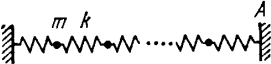


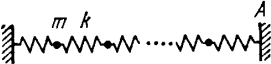

Lagrange function

$$
L=\frac{1}{2}\sum m{\dot{x}}_{n}^{2}-\frac{k}{2}{\sum }_{n=0}^{N}{\left({x}_{n+1}-{x}_{n}\right)}^{2}\\ {x}_{N+1}={x}_{0}=0
$$

EoMs:

$$
{\ddot{x}}_{n} \mathbf{=}\mathbf{-}{\omega }_{0}^{2}\left({x}_{n}-{x}_{n-1}\right)-{\omega }_{0}^{2}\left({x}_{n}-{x}_{n+1}\right) = {\omega }_{0}^{2}\left({x}_{n+1}+{x}_{n-1}-2{x}_{n}\right)
$$

The solution

$$
{x}_{n}={e}^{i\omega t}\left(A \sin{\left(qn\right)}+B \cos{\left(qn\right)}\right)\\ {x}_{0}=0\Rightarrow B=0,{x}_{N+1}=0\Rightarrow \sin{q\left(N+1\right)}=0\Rightarrow {q}_{k}=\frac{\pi }{N+1}k, k=1,2,...N
$$

$$
{\omega }_{k}=2{\omega }_{0}\sin{\frac{{q}_{k}}{2}}, {\lambda }_{k}=\frac{2\pi }{{q}_{k}}\\ {x}_{n}=\underset{k}{\sum }{C}_{k}{e}^{{i\omega }_{k}t}\sin{\left({q}_{k}n\right),\,\,\,\left(\text{to get physical coordinates we take real part}\right)}
$$

For $N\gg1$, the allowed wave vectors form an almost continuous set.

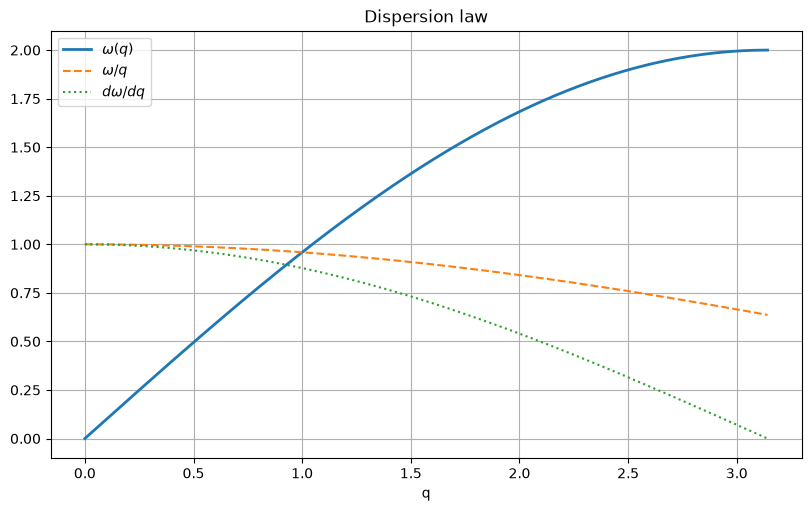

In [2]:
q=np.linspace(0,np.pi,501)
fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
ax.plot(q,2*np.sin(q/2),lw=2,label=r'$\omega(q)$')
ax.plot(q,np.sinc(q/(2*np.pi)),'--',label=r'$\omega/q$')
ax.plot(q,np.cos(q/2),':',label=r'$d\omega/dq$')
ax.set(xlabel='q',title='Dispersion law'); ax.legend(); ax.grid(); plt.show()

The group velocity tends to zero as $q\to\pi$. The long-wavelength sound speed is

$$
c = a {\omega }_{0}
$$

where a is the lattice spacing.

## Example 2


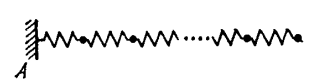


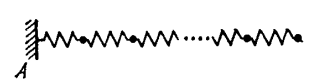

$$
L=\frac{1}{2}\sum m{\dot{x}}_{n}^{2}-\frac{k}{2}{\sum }_{n=1}^{N}{\left({x}_{n+1}-{x}_{n}\right)}^{2}, {x}_{0}=0,{x}_{N+1}={x}_{N}
$$

The solution:

$$
{x}_{n}={e}^{i\omega t}\left(A \sin{\left(qn\right)}+B \cos{\left(qn\right)}\right)\\ {x}_{0}=0\Rightarrow B=0,{x}_{N+1}={x}_{N}\Rightarrow \cos{\frac{q\left(2N+1\right)}{2}}\sin{\frac{q}{2}}=0\\ {q}_{k}=\frac{2k-1}{2N+1}\pi , k=1,...,N
$$

The boundary conditions determine the allowed values of $q$.

## Example 3


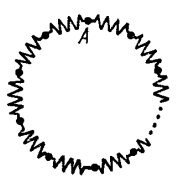


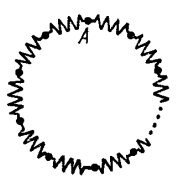

$$
L=\frac{1}{2}\sum m{\dot{x}}_{n}^{2}-\frac{k}{2}{\sum }_{n=0}^{N}{\left({x}_{n+1}-{x}_{n}\right)}^{2}, {x}_{0}={x}_{N},{x}_{1}={x}_{N+1}
$$

The solution:

$$
{x}_{n}={e}^{i\omega t}\left(A \sin{\left(qn\right)}+B \cos{\left(qn\right)}\right)\\ {x}_{0}=0\Rightarrow B=A \sin{\left(qN\right)}+B \cos{\left(qN\right)},\\ {x}_{N+1}={x}_{1}\Rightarrow A \left(\sin{\left(q\left(N+1\right)\right)}-\sin{q}\right)=B\left(\cos{q} -\cos{\left(q\left(N+1\right)\right)}\right)\\ {q}_{k}=\frac{2\pi  k}{N}\pi =2\pi -{q}_{N-k}, k=0,...,N-1
$$

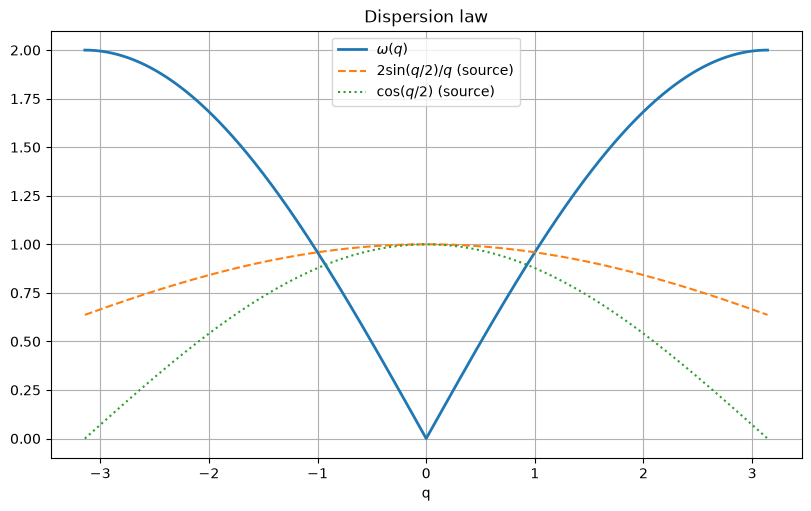

In [3]:
q=np.linspace(-np.pi,np.pi,1001)
fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
ax.plot(q,2*np.abs(np.sin(q/2)),lw=2,label=r'$\omega(q)$')
# Reproduce the two signed-branch expressions used in the original plot.
ax.plot(q,np.sinc(q/(2*np.pi)),'--',label=r'$2\sin(q/2)/q$ (source)')
ax.plot(q,np.cos(q/2),':',label=r'$\cos(q/2)$ (source)')
ax.set(xlabel='q',title='Dispersion law'); ax.legend(); ax.grid(); plt.show()
# For the positive-frequency branch, omega/q and domega/dq change sign at q=0.

Note that dω/dq →0 at q→±π

## Acoustic and Optic modes

When a unit cell contains several atoms, additional optical branches appear. With $s$ atoms per cell in $d$ dimensions, the dynamical matrix has size $sd\times sd$. In a polar crystal, relative displacements of oppositely charged ions can couple these modes to light; the optical branches have nonzero frequencies at zero wave vector.

## Example: diatomic chain


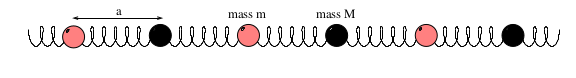


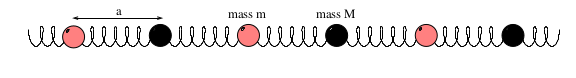

EoM’s

$$
{\ddot{x}}_{2n} \mathbf{=} -{\omega }_{m}^{2}\left(2{x}_{2n}-{x}_{2n+1}-{x}_{2n-1}\right)\\ {\ddot{x}}_{2n+1} \mathbf{=} {\omega }_{M}^{2}\left(2{x}_{2n+1}-{x}_{2n+2}-{x}_{2n}\right)
$$

Let masses $m$ occupy even sites and masses $M$ odd sites, with periodic boundary conditions. The translation period is doubled. Substituting

$$
{x}_{2n} \mathbf{=}A {e}^{i\left(\omega t - 2q n\right)}, {x}_{2n+1} \mathbf{=}B {e}^{i\left(\omega t - 2nq \right)}
$$

into the equations of motion gives the dispersion relation

$$
{\omega }_{\pm }^{2}={\omega }_{\mu }^{2}\left(1\pm \sqrt{1-4\frac{\mu }{m+M}\sin^{2}{q}}\right), \mu  = \frac{M m}{m+M}
$$

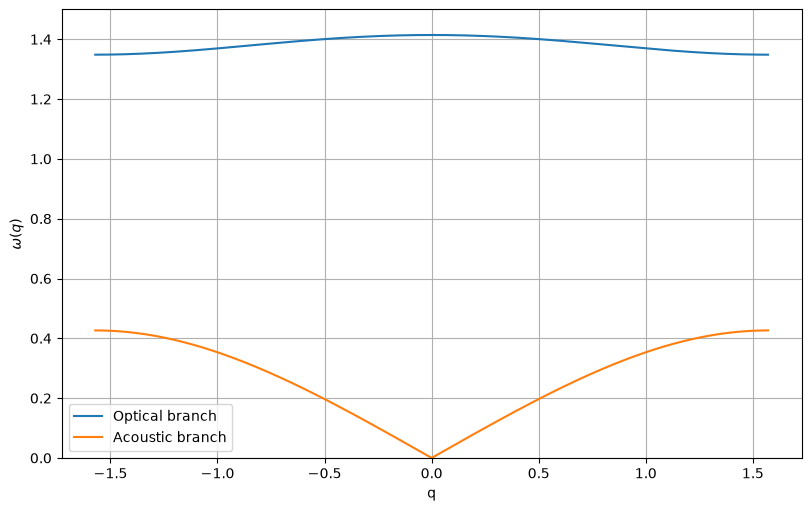

interactive(children=(FloatSlider(value=0.1, description='m', max=0.95, min=0.1, step=0.01), Output()), _dom_c…

In [4]:
def frequencies(q,m):
    inner=np.sqrt(np.clip(1-4*m/(1+m)**2*np.sin(q)**2,0,None))
    return np.sqrt(1+inner),np.sqrt(np.clip(1-inner,0,None))
def show_branches(m=.1):
    q=np.linspace(-np.pi/2,np.pi/2,801); optical,acoustic=frequencies(q,m)
    fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
    ax.plot(q,optical,label='Optical branch'); ax.plot(q,acoustic,label='Acoustic branch')
    ax.set(xlabel='q',ylabel=r'$\omega(q)$',ylim=(0,1.5)); ax.legend(); ax.grid(); plt.show()
show_branches()
branch_controls=widgets.interactive(show_branches,m=widgets.FloatSlider(min=.1,max=.95,step=.01,value=.1))
display(branch_controls)

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)